In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import joblib

import shap

from sklearn.model_selection import train_test_split
from scipy.special import expit

In [2]:
df = pd.read_csv('../data/processed/churn_engineered.csv')

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))
print("Number of features:", X_train.shape[1])

Training customers: 5634
Testing customers: 1409
Number of features: 37


In [3]:
final_model = joblib.load('../models/churn_model_final.pkl')

print(final_model)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [4]:
print("Dataset features:", X_test.shape[1])
print("Model features:", final_model.n_features_in_)

assert list(X_test.columns) == list(final_model.feature_names_in_)

print("Feature columns match with the saved model")

Dataset features: 37
Model features: 37
Feature columns match with the saved model


In [5]:
scaler = final_model.named_steps['standardscaler']

log_reg_model = final_model.named_steps['logisticregression']

print("Scelar:", scaler)
print("Model:", log_reg_model)

Scelar: StandardScaler()
Model: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)


In [6]:
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns = X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

display(X_test_scaled.head())

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,total_services,has_internet,high_risk_combo,charge_vs_service_avg,gender_Male,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_bucket_6-12mo,tenure_bucket_1-2yr,tenure_bucket_2+yr
437,-0.441773,1.031742,1.534786,1.608483,0.331885,0.831495,1.629976,2.706872,2.125633,0.524081,-0.597989,1.757089,0.994336,-0.331885,1.165042,1.126512,-0.524081,-0.524081,1.572053,-0.524081,1.359534,-0.524081,1.375572,-0.524081,1.554547,-0.524081,1.252163,-0.524081,1.247967,-0.512782,1.773611,1.909105,-0.710781,-0.543846,-0.334515,-0.412129,0.910942
2280,2.263606,-0.969234,-0.651557,-0.996684,0.331885,0.831495,1.168725,-0.610302,0.507935,0.524081,-0.597989,0.669835,-1.005696,-0.331885,1.165042,1.126512,-0.524081,-0.524081,-0.636111,-0.524081,-0.735546,-0.524081,-0.726971,-0.524081,1.554547,-0.524081,1.252163,-0.524081,1.247967,-0.512782,-0.563822,1.909105,-0.710781,-0.543846,2.989399,-0.412129,-1.097765
2235,-0.441773,1.031742,1.534786,0.346606,0.331885,0.831495,0.445324,0.400100,1.047168,0.524081,-0.597989,1.577024,-1.005696,-0.331885,1.165042,-0.887696,-0.524081,-0.524081,1.572053,-0.524081,1.359534,-0.524081,1.375572,-0.524081,-0.643274,-0.524081,1.252163,-0.524081,-0.801303,1.950146,-0.563822,1.909105,-0.710781,-0.543846,-0.334515,-0.412129,0.910942
4460,-0.441773,1.031742,-0.651557,-0.589626,0.331885,-1.202653,0.440347,-0.364487,-0.031297,0.524081,1.672273,-1.047087,0.994336,-0.331885,-0.858338,1.126512,-0.524081,-0.524081,-0.636111,-0.524081,-0.735546,-0.524081,1.375572,-0.524081,1.554547,-0.524081,-0.798618,-0.524081,-0.801303,-0.512782,-0.563822,-0.523806,1.406903,-0.543846,-0.334515,2.426423,-1.097765
3761,-0.441773,1.031742,-0.651557,1.608483,0.331885,0.831495,0.588013,1.588437,1.586400,0.524081,-0.597989,1.913368,-1.005696,-0.331885,1.165042,-0.887696,-0.524081,-0.524081,1.572053,-0.524081,1.359534,-0.524081,1.375572,-0.524081,-0.643274,-0.524081,1.252163,-0.524081,1.247967,-0.512782,1.773611,1.909105,-0.710781,-0.543846,-0.334515,-0.412129,0.910942


In [8]:
background = X_train_scaled.sample(
    n=200, random_state=42
)

print("Background Shape:", background.shape)

Background Shape: (200, 37)


In [10]:
masker = shap.maskers.Independent(background)

explainer = shap.LinearExplainer(
    log_reg_model, masker
)

print(explainer)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


In [11]:
shap_values = explainer(X_test_scaled)

print("SHAP values shape:", shap_values.values.shape)
print("Number of customers:", len(X_test_scaled))
print("Number of features:", X_test_scaled.shape[1])

SHAP values shape: (1409, 37)
Number of customers: 1409
Number of features: 37


In [12]:
# sanity check
customer_idx = 0

base_value = shap_values.base_values[customer_idx]

feature_contributions = shap_values.values[customer_idx].sum()

shap_log_odds = base_value + feature_contributions

shap_probability = expit(shap_log_odds)

model_probability = final_model.predict_proba(
    X_test.iloc[[customer_idx]]
)[0,1]

print("SHAP reconstructed probability:", shap_probability)
print("Model predicted probability:", model_probability)

print(
    "Difference:",
    abs(shap_probability - model_probability)
)

SHAP reconstructed probability: 0.11698811055435857
Model predicted probability: 0.11698811055435862
Difference: 5.551115123125783e-17


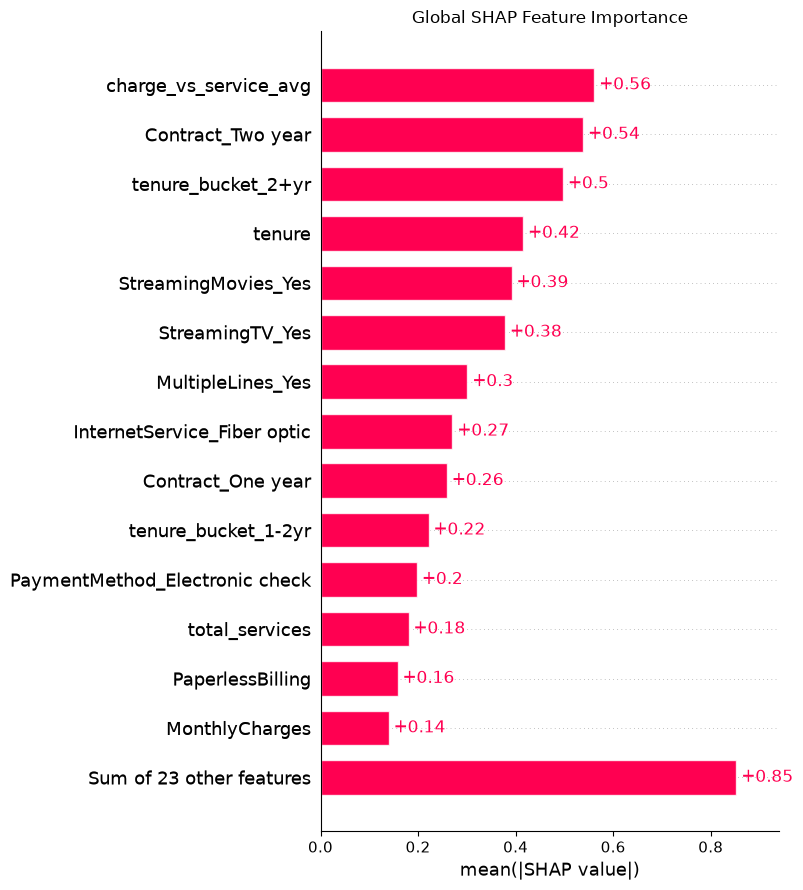

In [14]:
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

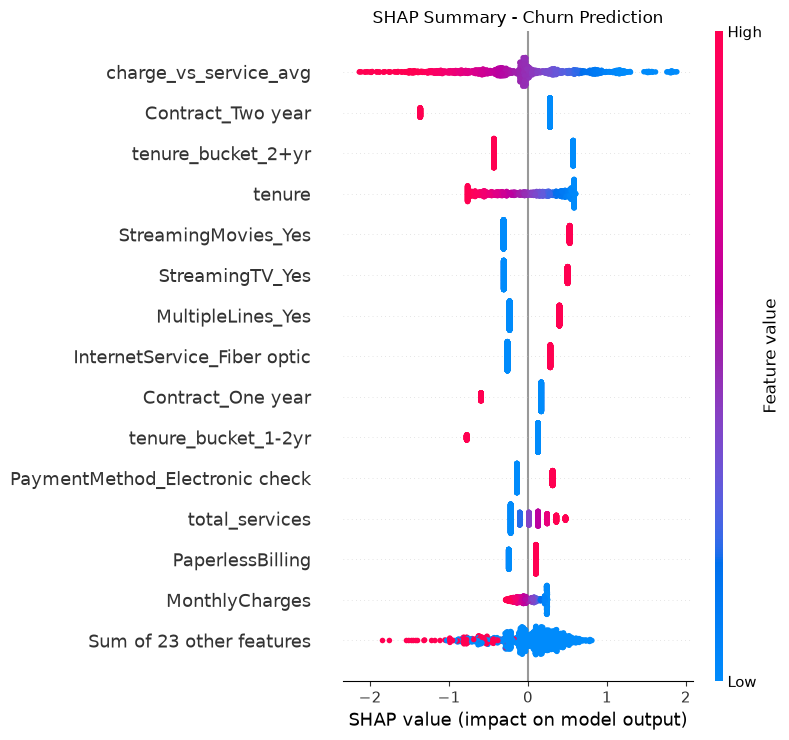

In [15]:
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("SHAP Summary - Churn Prediction")
plt.tight_layout()
plt.show()

In [16]:
y_proba = final_model.predict_proba(X_test)[:, 1]

customer_idx = np.argmax(y_proba)

print("Customer position:", customer_idx)
print("Predicted churn score:", round(y_proba[customer_idx], 4))
print("Actual churn:", y_test.iloc[customer_idx])

Customer position: 1090
Predicted churn score: 0.962
Actual churn: 1


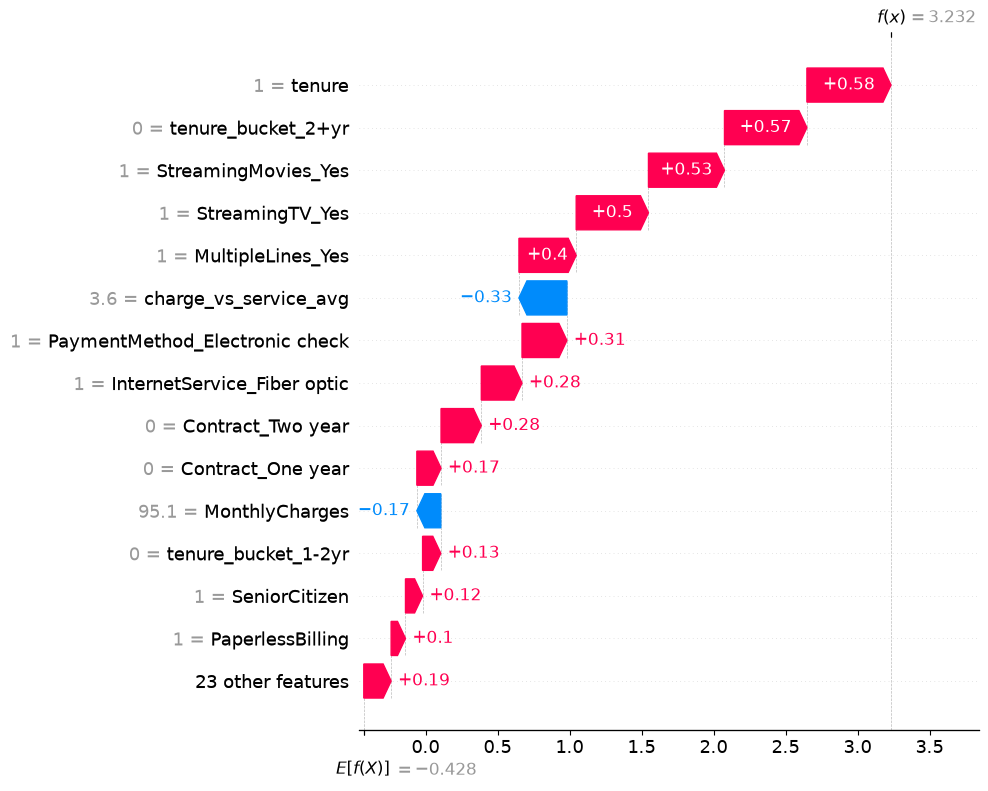

In [17]:
customer_explanation = shap_values[customer_idx]

customer_explanation.display_data = X_test.iloc[customer_idx].to_numpy()

shap.plots.waterfall(
    customer_explanation,
    max_display=15
)

SHAP analysis helped explain which customer characteristics influence the model's churn predictions.

Factors such as charges relative to service averages, contract duration, tenure, and streaming services. Longer tenure and long-term contracts generally reduced predicted churn risk, while short tenure, electronic-check payments, and certain service subscriptions increased it. 

The individual customer analysis showed how these factors contributed to a high churn-risk prediction of 96.2%.